# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "DaiGreco", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

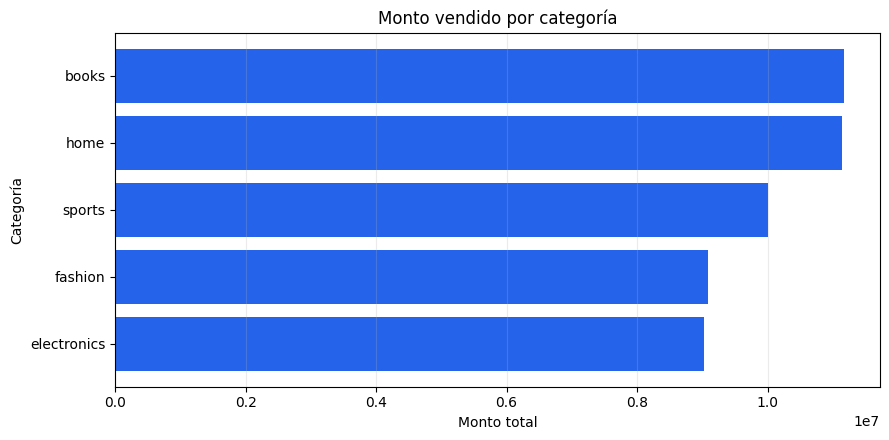

Respuesta: books es la categoría con mayor monto vendido (11,165,281.86).


In [0]:
category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#2563eb")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")

## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

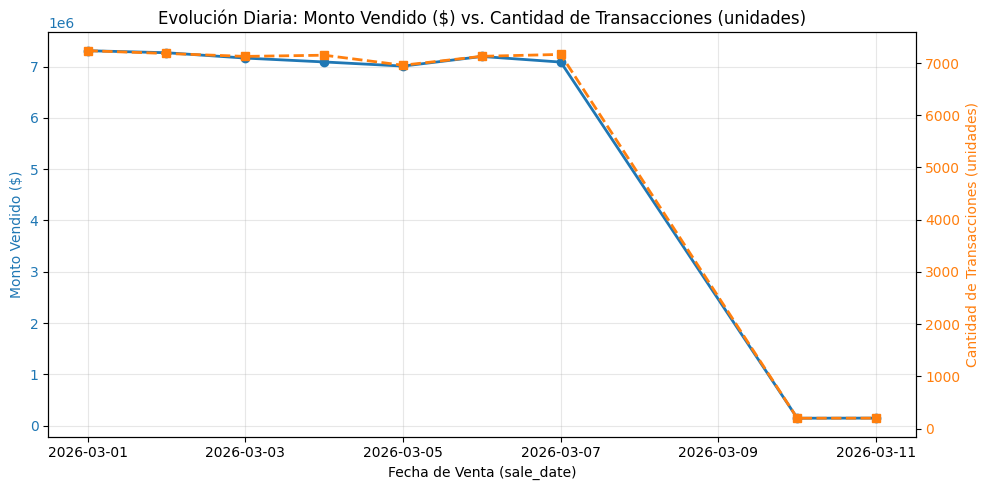

Día de mayor monto vendido: 2026-03-01 ($7,310,840.77)
Día de mayor cantidad de transacciones: 2026-03-01 (7236 transacciones)


In [0]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# 1. Agregación en PySpark usando sale_date antes de convertir a Pandas
df_agg = (
    spark.table(daily)
    .groupBy("sale_date")
    .agg(
        F.sum("total_amount").alias("monto_total"),
        F.sum("transaction_count").alias("cant_transacciones"),
    )
    .orderBy("sale_date")
)

# Convertir solo el resultado agregado a Pandas
df_plot = df_agg.toPandas()

# 2. Visualización con doble eje Y para no ocultar las unidades de cada métrica
fig, ax1 = plt.subplots(figsize=(10, 5))

# Eje principal (Izquierda): Monto vendido en pesos ($)
color_monto = "#1f77b4"
ax1.set_xlabel("Fecha de Venta (sale_date)")
ax1.set_ylabel("Monto Vendido ($)", color=color_monto)
line1 = ax1.plot(
    df_plot["sale_date"],
    df_plot["monto_total"],
    color=color_monto,
    marker="o",
    linewidth=2,
    label="Monto Vendido ($)",
)
ax1.tick_params(axis="y", labelcolor=color_monto)
ax1.grid(True, alpha=0.3)

# Eje secundario (Derecha): Cantidad de transacciones (Unidades/Cantidades)
ax2 = ax1.twinx()
color_cant = "#ff7f0e"
ax2.set_ylabel("Cantidad de Transacciones (unidades)", color=color_cant)
line2 = ax2.plot(
    df_plot["sale_date"],
    df_plot["cant_transacciones"],
    color=color_cant,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Cant. Transacciones",
)
ax2.tick_params(axis="y", labelcolor=color_cant)

# Título claro
plt.title(
    "Evolución Diaria: Monto Vendido ($) vs. Cantidad de Transacciones (unidades)"
)
fig.tight_layout()
plt.show()

# 3. Identificación de máximos para formular la respuesta escrita
max_monto = df_agg.orderBy(F.desc("monto_total")).first()
max_trans = df_agg.orderBy(F.desc("cant_transacciones")).first()

print(
    f"Día de mayor monto vendido: {max_monto['sale_date']} (${max_monto['monto_total']:,.2f})"
)
print(
    f"Día de mayor cantidad de transacciones: {max_trans['sale_date']} ({max_trans['cant_transacciones']} transacciones)"
)

##Conclusion
Revisando el resultado noto que existe coincidencia entre el día de mayor monto vendido y el día de mayor cantidad de transacciones, esto puede deberse a que el monto vendido es la suma de todas las transacciones realizadas en ese día, por lo tanto, el día con mayor monto vendido es el mismo que el día con mayor cantidad de transacciones.

## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

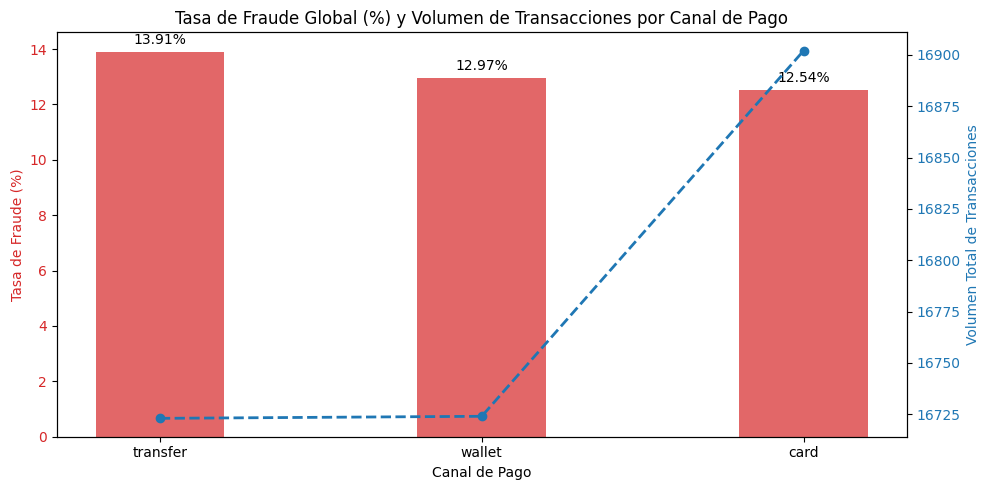

=== Resumen por Canal de Pago ===
payment_channel  fraud_rate  total_fraud  total_transactions
       transfer       13.91         2327               16723
         wallet       12.97         2169               16724
           card       12.54         2119               16902


In [0]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# 1. Agregación global en PySpark por canal de pago
df_payment = (
    spark.table(daily)
    .groupBy("payment_channel")
    .agg(
        F.sum("fraud_transactions").alias("total_fraud"),
        F.sum("transaction_count").alias("total_transactions"),
    )
    .withColumn(
        "fraud_rate",
        F.round((F.col("total_fraud") / F.col("total_transactions")) * 100, 2),
    )
    .orderBy(F.desc("fraud_rate"))
)

# Convertir el resultado agregado a Pandas
df_payment_pd = df_payment.toPandas()

# 2. Visualización combinada (Tasa de fraude vs. Volumen total de transacciones)
fig, ax1 = plt.subplots(figsize=(10, 5))

# Eje 1 (Barras): Tasa de fraude global (%)
color_bar = "#d62728"
bars = ax1.bar(
    df_payment_pd["payment_channel"],
    df_payment_pd["fraud_rate"],
    color=color_bar,
    alpha=0.7,
    width=0.4,
    label="Tasa de Fraude (%)",
)
ax1.set_xlabel("Canal de Pago")
ax1.set_ylabel("Tasa de Fraude (%)", color=color_bar)
ax1.tick_params(axis="y", labelcolor=color_bar)

# Añadir valores numéricos sobre cada barra
for bar in bars:
    height = bar.get_height()
    ax1.annotate(
        f"{height:.2f}%",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
    )

# Eje 2 (Línea/Puntos): Volumen total de transacciones
ax2 = ax1.twinx()
color_line = "#1f77b4"
ax2.plot(
    df_payment_pd["payment_channel"],
    df_payment_pd["total_transactions"],
    color=color_line,
    marker="o",
    linewidth=2,
    linestyle="--",
    label="Volumen Total Transacciones",
)
ax2.set_ylabel("Volumen Total de Transacciones", color=color_line)
ax2.tick_params(axis="y", labelcolor=color_line)

plt.title("Tasa de Fraude Global (%) y Volumen de Transacciones por Canal de Pago")
fig.tight_layout()
plt.show()

# 3. Mostrar resumen en consola
print("=== Resumen por Canal de Pago ===")
print(
    df_payment_pd[
        ["payment_channel", "fraud_rate", "total_fraud", "total_transactions"]
    ].to_string(index=False)
)

##Conclusion:
Revisando el resultado noto que el canal de pago con mayor tasa de fraude es transfer pese a ser el canal de pago con menor volumen total de transacciones, esto nos indica que es necesario revisar el canal de pago transfer para detectar y prevenir fraudes.Tambien podemos observar que el canal con mayor numero de transacciones es card pese a tener menor tasa de fraude.

## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

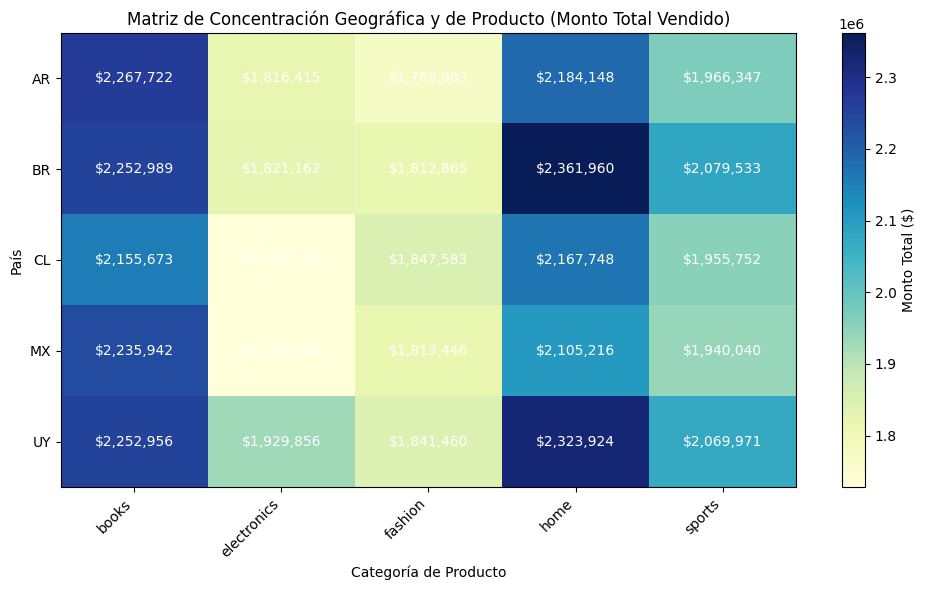

=== MÁXIMO GLOBAL ===
La combinación con mayor monto vendido es: BR - home ($2,361,959.97)


In [0]:
import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql import functions as F

# 1. Agregación en PySpark por país y categoría
df_country_cat = (
    spark.table(daily)
    .groupBy("country", "category")
    .agg(F.sum("total_amount").alias("monto_total"))
    .orderBy("country", "category")
)

# Convertimos a Pandas
df_country_cat_pd = df_country_cat.toPandas()

# Convertimos explícitamente a float para evitar el error de 'dtype object'
df_country_cat_pd["monto_total"] = df_country_cat_pd["monto_total"].astype(
    float
)

pivot_df = df_country_cat_pd.pivot(
    index="country", columns="category", values="monto_total"
).astype(float)

# 2. Visualización mediante Mapa de Calor nativo con Matplotlib
fig, ax = plt.subplots(figsize=(10, 6))
cax = ax.imshow(pivot_df.values, cmap="YlGnBu", aspect="auto")

# Configurar ejes con las etiquetas de países y categorías
ax.set_xticks(np.arange(len(pivot_df.columns)))
ax.set_yticks(np.arange(len(pivot_df.index)))
ax.set_xticklabels(pivot_df.columns, rotation=45, ha="right")
ax.set_yticklabels(pivot_df.index)

# Agregar la barra de color (leyenda)
cbar = fig.colorbar(cax)
cbar.set_label("Monto Total ($)")

# Anotar los valores dentro de cada celda
max_val = np.nanmax(pivot_df.values)
for i in range(len(pivot_df.index)):
    for j in range(len(pivot_df.columns)):
        val = pivot_df.iloc[i, j]
        if not np.isnan(val):
            ax.text(
                j,
                i,
                f"${val:,.0f}",
                ha="center",
                va="center",
                color="black" if val < max_val * 0.7 else "white",
            )

plt.title(
    "Matriz de Concentración Geográfica y de Producto (Monto Total Vendido)"
)
plt.xlabel("Categoría de Producto")
plt.ylabel("País")
plt.tight_layout()
plt.show()

# 3. Máximo global
max_global = df_country_cat.orderBy(F.desc("monto_total")).first()

print(f"=== MÁXIMO GLOBAL ===")
print(
    f"La combinación con mayor monto vendido es: {max_global['country']} - {max_global['category']} (${max_global['monto_total']:,.2f})"
)

##Conclusiones

Observando los resultados notamos que el pais con mayor monto total vendido es Brasil - Home y la combinacion con menor monto de ventas es mexico - electronics.
La categoria mas dominante es home seguido de books y de sports.

## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

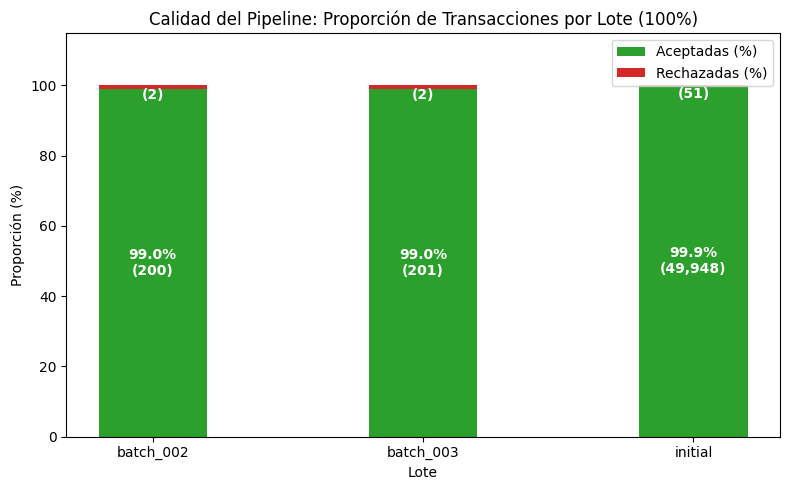

=== Resumen de Calidad por Lote ===
  lote_id  total_transactions  accepted_transactions  rejected_transactions  prop_accepted  prop_rejected
batch_002                 202                    200                      2          99.01           0.99
batch_003                 203                    201                      2          99.01           0.99
  initial               49999                  49948                     51          99.90           0.10


In [0]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

df_raw = spark.table(batch)

# Identificar la columna que corresponde al ID del lote/batch
cols = df_raw.columns
batch_col = None

for c in cols:
    if "batch" in c.lower() or "lote" in c.lower() or "id" in c.lower():
        if c not in [
            "accepted_transactions",
            "rejected_transactions",
            "total_amount",
            "refreshed_at",
        ]:
            batch_col = c
            break

# 1. Agregación y cálculo de proporciones en PySpark
if batch_col:
    df_batch = df_raw.withColumn("lote_id", F.col(batch_col))
else:
    # Si no hay columna de lote explicitada, creamos una etiqueta secuencial o usamos refreshed_at
    from pyspark.sql.window import Window

    windowSpec = Window.orderBy("refreshed_at")
    df_batch = df_raw.withColumn(
        "lote_id",
        F.concat(F.lit("Lote "), F.row_number().over(windowSpec).cast("string")),
    )

df_batch = (
    df_batch.withColumn(
        "total_transactions",
        F.col("accepted_transactions") + F.col("rejected_transactions"),
    )
    .withColumn(
        "prop_accepted",
        F.round(
            (F.col("accepted_transactions") / F.col("total_transactions")) * 100,
            2,
        ),
    )
    .withColumn(
        "prop_rejected",
        F.round(
            (F.col("rejected_transactions") / F.col("total_transactions")) * 100,
            2,
        ),
    )
    .orderBy("lote_id")
)

# Convertir a Pandas para graficar
df_batch_pd = df_batch.toPandas()

# 2. Gráfico de barras apiladas al 100%
fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(
    df_batch_pd["lote_id"],
    df_batch_pd["prop_accepted"],
    label="Aceptadas (%)",
    color="#2ca02c",
    width=0.4,
)
bars2 = ax.bar(
    df_batch_pd["lote_id"],
    df_batch_pd["prop_rejected"],
    bottom=df_batch_pd["prop_accepted"],
    label="Rechazadas (%)",
    color="#d62728",
    width=0.4,
)

# Anotar porcentajes y cantidades dentro de las barras
for i, row in df_batch_pd.iterrows():
    # Porcentaje aceptado
    ax.text(
        i,
        row["prop_accepted"] / 2,
        f"{row['prop_accepted']:.1f}%\n({int(row['accepted_transactions']):,})",
        ha="center",
        va="center",
        color="white",
        weight="bold",
    )
    # Porcentaje rechazado
    ax.text(
        i,
        row["prop_accepted"] + (row["prop_rejected"] / 2),
        f"{row['prop_rejected']:.1f}%\n({int(row['rejected_transactions']):,})",
        ha="center",
        va="center",
        color="white",
        weight="bold",
    )

ax.set_ylabel("Proporción (%)")
ax.set_xlabel("Lote")
ax.set_title("Calidad del Pipeline: Proporción de Transacciones por Lote (100%)")
ax.set_ylim(0, 115)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

# 3. Impresión del resumen numérico
print("=== Resumen de Calidad por Lote ===")
print(
    df_batch_pd[
        [
            "lote_id",
            "total_transactions",
            "accepted_transactions",
            "rejected_transactions",
            "prop_accepted",
            "prop_rejected",
        ]
    ].to_string(index=False)
)

##Conclusion

Observando los resultados notamos que  lotes 2 y 3 tienen la misma cantidad de rejects. Tambien observamos que el lote Inicial es el de mayor cantidad de aceptados y proporcion de aceptadados. 

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.